In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -------- CONFIGURATION --------
path = ""
merged_file = f"{path}merged_nodups_1.pairs"
output_plot = f"{path}distance_decay_from_merged_nodups_first10k.png"
distance_bin_size = 1000  

# -------- LOAD & PROCESS --------
# Format assumption: chr1, pos1, chr2, pos2, ... (5+ columns)
df = pd.read_csv(merged_file, sep=" ", header=None,
                 usecols=[0, 1, 2, 3],
                 names=["chr1", "pos1", "chr2", "pos2"])

print("Total read pairs loaded:", len(df))
print(df[:10])

# Filter for intra-chromosomal contacts
df = df[df["chr1"] == df["chr2"]].copy()

print("Intra-chromosomal pairs:", len(df))

# Calculate genomic distance
df["distance"] = np.abs(df["pos1"] - df["pos2"])

# Filter out zero distance and optionally limit range
df = df[df["distance"] > 0]

print("Nonzero-distance pairs:", len(df))

max_distance = 100_000_000  # Optional: ignore extremely long distances
df = df[df["distance"] <= max_distance]

print("Pairs after max distance filter:", len(df))

# Bin distances
df["distance_bin"] = (df["distance"] // distance_bin_size) * distance_bin_size
distance_summary = df.groupby("distance_bin").size().reset_index(name="read_count")

# Log transform
distance_summary["log_distance"] = np.log10(distance_summary["distance_bin"])
distance_summary["log_read_count"] = np.log10(distance_summary["read_count"] + 1)





Total read pairs loaded: 1058692445
    chr1   pos1   chr2       pos2
0  chr10  10463  chr10   58488150
1  chr10  10412  chr10  132316131
2  chr10  10256  chr10  132953522
3  chr10  10424  chr10   99054210
4  chr10  10410  chr10  119599951
5  chr10  10418  chr10  107081632
6  chr10  10831  chr10    3831682
7  chr10  10809  chr10   21389278
8  chr10  10820  chr10     342829
9  chr10  10810  chr10    1434821
Intra-chromosomal pairs: 921678948
Nonzero-distance pairs: 921610480
Pairs after max distance filter: 918037732


/mnt/programs/anaconda3/lib/python3.7/site-packages/pandas/core/arraylike.py:364: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [41]:
distance_summary.to_csv(f"{path}distance_summary.tsv", sep="\t", index=False)

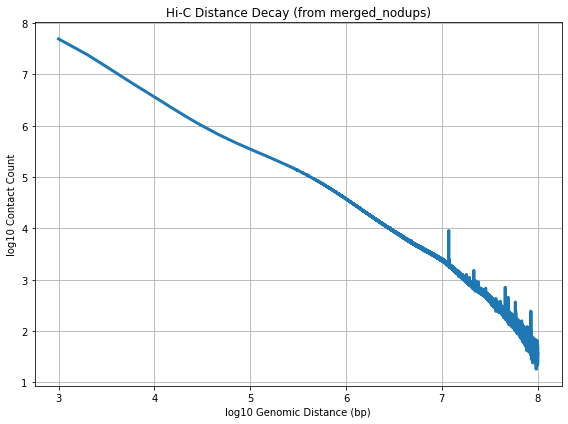

In [27]:
# -------- PLOT --------
plt.figure(figsize=(8, 6))
sns.lineplot(x="log_distance", y="log_read_count", data=distance_summary, linewidth = 3)
plt.xlabel("log10 Genomic Distance (bp)")
plt.ylabel("log10 Contact Count")
#plt.ylim(4,8)
#plt.xlim(4,6.9)
plt.title("Hi-C Distance Decay (from merged_nodups)")
plt.grid(True)
plt.tight_layout()
plt.savefig(output_plot, dpi=300)
plt.show()

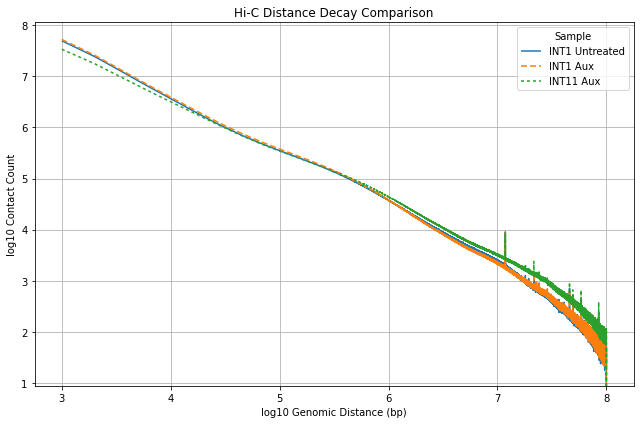

In [ ]:
# -------- FILE PATHS --------
files = {
    "INT1 Untreated": "INT1_Untreated_distance_summary.tsv",
    "INT1 Aux": "INT1_Aux4hr_distance_summary.tsv",
    "INT11 Aux": "INTS11_Aux4hr_distance_summary.tsv"
}

# -------- LOAD & COMBINE --------
dfs = []
for name, path in files.items():
    df = pd.read_csv(path, sep="\t")
    df["Sample"] = name
    df["log_distance"] = np.log10(df["distance_bin"])
    df["log_read_count"] = np.log10(df["read_count"] + 1)  # avoid log(0)
    dfs.append(df)

combined_df = pd.concat(dfs, ignore_index=True)

# -------- PLOT --------
plt.figure(figsize=(9, 6))
sns.lineplot(data=combined_df, x="log_distance", y="log_read_count", hue="Sample", style= "Sample",
            dashes={"INT1 Untreated": (1, 0), "INT1 Aux": (4, 2), "INT11 Aux": (2, 2)})
plt.xlabel("log10 Genomic Distance (bp)")
plt.ylabel("log10 Contact Count")
plt.title("Hi-C Distance Decay Comparison")
#plt.xlim(3,3.5)
#plt.ylim(7,8)
plt.ylim(.95,8.05)
plt.grid(True)
plt.tight_layout()
plt.savefig("distance_decay_comparison.png", dpi=300)
plt.show()